# Lesotho POI data: one dual-mode GNN for business location intelligence

**Input:** `poi_engineered.csv` (6,083 nodes, 66 features with the prefixes `loc_`, `adm_`, `struct_`, `attr_`, `ctx_`).
**Output:** `model_outputs_v2/` (trained models, out-of-fold predictions in both modes, metrics) and
`model_outputs_v2/training_progress.log`, which a separate terminal window follows live.

**Why a second iteration.** `model.ipynb` (iteration 1) reached test macro-F1 0.375 under spatial CV, but its
ablations showed that the signal comes from how each POI was mapped (`attr_`: named or not, outline or point,
address, opening hours). Geography and the graph alone gave 0.235. Chapter 1 (Section 1.6) notes that these
attributes do not exist for an empty candidate site, so that model cannot score a site where no business stands yet,
which the study aim (co-location patterns, market gaps, suitable areas) requires. In design-science terms, the
evaluation of iteration 1 fed back into a new design.

**The design: one model, two input modes.**

| Mode | Node's own mapping attributes | Used for |
|---|---|---|
| **Known POI** | visible | classifying existing POIs (RO1, RO4) |
| **Site** | hidden, with a flag "attributes unknown" | what the location and its neighbours imply (RO2, RO3, RO4) |

The same weights serve both modes. During training, the own-node attributes of a random part of the loss nodes are
hidden, in the same way the label trick hides labels, so the model learns to predict from location and neighbours
when a node's attributes are missing.

**Changes from iteration 1.**

1. **Attribute masking** (above). Masked columns: the 8 `attr_` features and the two `ctx_` features that compare
   the node with its neighbours (`ctx_osm_id_rank_vs_k32`, `ctx_footprint_vs_k32`). The other `ctx_` features
   describe the 32 nearest *other* nodes, so they exist for a candidate site too.
2. **Label trick with a random label rate.** Neighbour categories (co-location) are fed as inputs from the
   training folds only. The share of visible training labels is drawn anew each epoch, so the model also learns to
   cope with neighbourhoods where few labels are known, as in a held-out fold.
3. **Label reuse at test time.** Confident predictions for nodes outside the training folds are fed back as visible
   labels and the model is run again. No test label is used. At deployment every existing POI's category is known,
   so this brings the evaluation closer to how the model is used.
4. **Distance-weighted edges.** k = 8 links rural POIs kilometres apart; neighbours are weighted by
   distance (a softmax over -d / scale for each node), with the scale tuned and "no weighting" as one option.
5. **Temperature scaling** fitted on validation, in place of the per-class offsets that did not transfer in
   iteration 1. It leaves the predicted class unchanged and makes the probabilities usable as expected counts for
   the market-gap analysis.

**Evaluation** is unchanged: 5-fold spatial CV on 5 km blocks (test fold *f*, validation fold *f* + 1), macro-F1
as the main score, selection on validation only. Every result is reported in both modes. The site-mode score is the
honest measure of the location intelligence.

In [1]:
import copy
import itertools
import json
import subprocess
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy.spatial import cKDTree
from sklearn.metrics import f1_score, precision_recall_fscore_support

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="IProgress not found")   # tqdm notice from a PyG import
warnings.filterwarnings("ignore", message=".*torch.jit.script.*")
import torch
import torch.nn as nn
import torch.nn.functional as Fn
from torch_geometric.nn import GATv2Conv, GCNConv, MessagePassing
from torch_geometric.utils import contains_isolated_nodes, contains_self_loops, is_undirected, softmax, to_undirected

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)

IN_CSV = "poi_engineered.csv"
OUT_DIR = Path("model_outputs_v2")
OUT_DIR.mkdir(exist_ok=True)
LOG_PATH = OUT_DIR / "training_progress.log"
FEAT_RE = r"^(loc|adm|struct|attr|ctx)_"
K = 8               # k-NN graph used by the EDA, the structural encodings and the model
SEED = 42
N_FOLDS = 5
torch.set_num_threads(4)

# Chart styling (same as the earlier notebooks)
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#f4f8fd", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5",
                                                     "#256abf", "#184f95", "#0d366b"])
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"], "font.size": 9.5,
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "figure.dpi": 100, "legend.frameon": False,
})


def log(msg):
    """Append a timestamped line to the progress log (ASCII only, so any terminal shows it cleanly)."""
    line = f"{time.strftime('%H:%M:%S')}  {msg}"
    with open(LOG_PATH, "a", encoding="ascii", errors="replace") as fh:
        fh.write(line + "\n")


# Live progress: a separate terminal window follows the log while the model trains (Windows only; opened once)
OPEN_PROGRESS_WINDOW = True
LOG_PATH.write_text("", encoding="ascii")
log("GNN training progress log - gnn_location_model.ipynb (dual-mode GNN)")
if OPEN_PROGRESS_WINDOW and sys.platform == "win32" and not globals().get("_progress_window_opened"):
    subprocess.Popen(
        ["powershell", "-NoExit", "-Command",
         f"$host.UI.RawUI.WindowTitle = 'GNN training progress (dual-mode)'; "
         f"Get-Content -LiteralPath '{LOG_PATH.resolve()}' -Wait -Tail 60"],
        creationflags=subprocess.CREATE_NEW_CONSOLE)
    _progress_window_opened = True

df = pd.read_csv(IN_CSV, keep_default_na=False, na_values=[""])
FEATS = df.filter(regex=FEAT_RE).columns.tolist()
N = len(df)
assert df["node_id"].tolist() == list(range(N))
assert np.isfinite(df[FEATS].to_numpy(float)).all()
labelled = df["is_labelled"].eq(1).to_numpy()
y_np = df["label"].to_numpy()
fold_np = df["fold"].to_numpy()
CATS = df.loc[labelled].sort_values("label")["category"].unique().tolist()   # label order 0..7
C = len(CATS)

print(f"torch {torch.__version__} | CPU threads {torch.get_num_threads()} | progress log: {LOG_PATH.resolve()}")
print(f"{N:,} nodes x {df.shape[1]} columns | {len(FEATS)} features | labelled {labelled.sum():,} | "
      f"unlabelled {(~labelled).sum()}")
print("Classes (label order):", CATS)
print(pd.crosstab(df.loc[labelled, "category"], df.loc[labelled, "fold"], margins=True).loc[CATS + ["All"]])

torch 2.14.0+cpu | CPU threads 4 | progress log: C:\Users\BrainTech\Documents\DevDox\research\poi_business\POIs\model_outputs_v2\training_progress.log
6,083 nodes x 92 columns | 66 features | labelled 5,952 | unlabelled 131
Classes (label order): ['Infrastructure', 'Educational', 'Retail', 'Other', 'Food & Beverage', 'Tourism', 'Religious', 'Healthcare']
fold                0     1     2     3     4   All
category                                           
Infrastructure    362   367   349   354   360  1792
Educational       353   341   339   389   244  1666
Retail            191   232   251   217   290  1181
Other              63    61    70    60    80   334
Food & Beverage    67    66    40    48    72   293
Tourism            59    45    47    55    46   252
Religious          42    47    57    53    37   236
Healthcare         45    39    30    32    52   198
All              1182  1198  1183  1208  1181  5952


## 1. Graph, features, site-mode masking and spatial CV splits

- **Edges:** k = 8 nearest neighbours from `x_km`/`y_km`, undirected, self excluded (as in iteration 1). Each edge
  also carries its length in metres, used for the distance weights.
- **Features:** the 66 prefixed columns plus one flag, `own_attrs_hidden`. The continuous columns are standardised
  with a mean and SD fitted on the non-test folds of each split; the binary columns stay 0/1.
- **Site mode:** for a masked node, the 10 own-node columns are set to 0 (the training mean for a standardised
  column) and the flag to 1, so the model can tell "attribute hidden" from "attribute absent".
- **Splits:** test fold *f*, validation fold *(f + 1) mod 5*, the other three folds train; the 131 unlabelled nodes
  stay in the graph as neighbours.

In [2]:
# k = 8 nearest-neighbour graph (identical to the one the struct_ features describe)
xy = df[["x_km", "y_km"]].to_numpy() * 1000
_, nn_i = cKDTree(xy).query(xy, k=K + 2)
nn_i = nn_i[nn_i != np.arange(N)[:, None]].reshape(N, K + 1)[:, :K]      # drop self explicitly
EDGE_INDEX = to_undirected(torch.tensor(np.vstack([np.repeat(np.arange(N), K), nn_i.ravel()])), num_nodes=N)
assert is_undirected(EDGE_INDEX) and not contains_self_loops(EDGE_INDEX)
assert not contains_isolated_nodes(EDGE_INDEX, N)
SRC, DST = EDGE_INDEX                                   # messages flow SRC -> DST
deg = np.bincount(DST.numpy(), minlength=N)
EDGE_DIST = torch.tensor(np.hypot(*(xy[SRC.numpy()] - xy[DST.numpy()]).T), dtype=torch.float32)   # metres


def edge_weights(scale):
    """Weights of the incoming edges of each node, summing to 1 per node: softmax(-d / scale), or the plain mean
    when scale is None. Computed as a softmax, so far-apart rural neighbourhoods do not underflow."""
    if scale is None:
        return 1.0 / torch.tensor(deg, dtype=torch.float32)[DST]
    return softmax(-EDGE_DIST / scale, DST, num_nodes=N)


# Own-node columns: hidden in site mode (they describe how this node itself was mapped)
OWN_COLS = [c for c in FEATS if c.startswith("attr_")] + ["ctx_osm_id_rank_vs_k32", "ctx_footprint_vs_k32"]
assert len(OWN_COLS) == 10 and all(c in FEATS for c in OWN_COLS)
BINARY = [c for c in FEATS if set(np.unique(df[c])) <= {0, 1}]
OSM_RANK = [c for c in FEATS if "osm_id_rank" in c]
GROUPS = ["loc", "adm", "struct", "attr", "ctx"]


def make_x(feats, test_fold):
    """Feature matrix for one split (standardised on the non-test folds' rows), plus the own_attrs_hidden flag as
    the last column. Returns the matrix and the column indices that site mode hides."""
    X = df[feats].to_numpy(np.float64).copy()
    fit_rows = fold_np != test_fold
    cols = [j for j, c in enumerate(feats) if c not in BINARY]
    mu, sd = X[fit_rows][:, cols].mean(0), X[fit_rows][:, cols].std(0)
    sd[sd == 0] = 1.0
    X[:, cols] = (X[:, cols] - mu) / sd
    X = np.c_[X, np.zeros(N)]
    own_idx = torch.tensor([j for j, c in enumerate(feats) if c in OWN_COLS] + [len(feats)])
    return torch.tensor(X, dtype=torch.float32), own_idx


def mask_own(x, own_idx, nodes):
    """Site mode for `nodes`: own-node columns to 0, flag (last entry of own_idx) to 1."""
    x = x.clone()
    rows = nodes.unsqueeze(1)
    x[rows, own_idx[:-1]] = 0.0
    x[nodes, own_idx[-1]] = 1.0
    return x


def make_split(test_fold):
    """Boolean masks over nodes (labelled only): train on 3 folds, validate on the next fold, test on test_fold."""
    val_fold = (test_fold + 1) % N_FOLDS
    train = labelled & (fold_np != test_fold) & (fold_np != val_fold)
    val = labelled & (fold_np == val_fold)
    test = labelled & (fold_np == test_fold)
    return {"test_fold": test_fold, "val_fold": val_fold, "train": torch.tensor(train),
            "val": torch.tensor(val), "test": torch.tensor(test)}


SPLITS = [make_split(f) for f in range(N_FOLDS)]
Y = torch.tensor(np.where(labelled, y_np, 0))          # unlabelled nodes get a dummy 0; they are in no mask

print(f"Graph: {N:,} nodes, {EDGE_INDEX.size(1) // 2:,} undirected edges, degree {deg.min()} to {deg.max()} "
      f"(median {int(np.median(deg))})")
q = np.percentile(EDGE_DIST.numpy(), [10, 50, 90, 99])
print("Edge length (m): 10% {:.0f} | median {:.0f} | 90% {:.0f} | 99% {:.0f} | max {:.0f}".format(
    *q, EDGE_DIST.max().item()))
eff = {}
for s in [None, 1000, 250]:
    w = edge_weights(s)
    assert torch.allclose(torch.zeros(N).index_add_(0, DST, w), torch.ones(N), atol=1e-5)
    eff[f"scale {s} m" if s else "no weighting"] = np.median(1 / torch.zeros(N).index_add_(0, DST, w ** 2).numpy())
print("Effective number of neighbours per node (median):", {k: round(float(v), 1) for k, v in eff.items()})

print(f"\nFeatures: {len(FEATS)} + 1 flag | own-node columns hidden in site mode ({len(OWN_COLS)}): {OWN_COLS}")
x0, own0 = make_x(FEATS, 0)
xm = mask_own(x0, own0, torch.tensor([0, 1]))
assert (xm[[0, 1]][:, own0[:-1]] == 0).all() and (xm[[0, 1], -1] == 1).all() and (x0[:, -1] == 0).all()
assert torch.equal(xm[2:], x0[2:])

# How many labelled neighbours a node sees when only the training folds' labels are visible
rows = []
for s in SPLITS:
    tr = s["train"].numpy()
    vis_share = np.bincount(DST.numpy(), weights=tr[SRC.numpy()], minlength=N) / deg
    rows.append({"test fold": s["test_fold"], "train": int(tr.sum()), "val": int(s["val"].sum()),
                 "test": int(s["test"].sum()),
                 "labelled-neighbour share: train nodes": vis_share[tr].mean(),
                 "val nodes": vis_share[s["val"].numpy()].mean(), "test nodes": vis_share[s["test"].numpy()].mean(),
                 "test nodes with none": (vis_share[s["test"].numpy()] == 0).mean()})
print(pd.DataFrame(rows).round(3).to_string(index=False))

Graph: 6,083 nodes, 31,452 undirected edges, degree 8 to 20 (median 10)
Edge length (m): 10% 67 | median 563 | 90% 4545 | 99% 8397 | max 17778
Effective number of neighbours per node (median): {'no weighting': 10.0, 'scale 1000 m': 8.2, 'scale 250 m': 5.0}

Features: 66 + 1 flag | own-node columns hidden in site mode (10): ['attr_has_name', 'attr_has_address', 'attr_has_hours', 'attr_has_footprint', 'attr_log_footprint_m2', 'attr_is_point', 'attr_quality_score', 'attr_osm_id_rank', 'ctx_osm_id_rank_vs_k32', 'ctx_footprint_vs_k32']
 test fold  train  val  test  labelled-neighbour share: train nodes  val nodes  test nodes  test nodes with none
         0   3572 1198  1182                                  0.859      0.211       0.207                 0.443
         1   3571 1183  1198                                  0.873      0.169       0.201                 0.457
         2   3561 1208  1183                                  0.866      0.214       0.178                 0.474
         3 

**Findings.** Edges range from 67 m (10th percentile) to 4.5 km (90th): in towns k = 8 links buildings on one
street, in the countryside it links villages. With a 250 m scale a node effectively averages 5 of its neighbours
instead of 10, so the weighting changes what the model sees.

The last table shows why the label trick added little in iteration 1. When the training folds' labels are visible,
a training node sees a labelled category on **86%** of its incoming edges, but a test node only on **11 to 24%**, and
**42 to 73%** of test nodes have no labelled neighbour at all. Fold 4, the urban Maseru fold that was weakest in
iteration 1, is the extreme case (73%). A model trained with half of its neighbours labelled meets mostly
unlabelled neighbourhoods at test time. The random label rate (training) and label reuse (test) address this gap.

## 2. The model, training in two modes, and evaluation

**Architecture** (as in iteration 1, so the comparison isolates the changes): a linear encoder of the node's
features and its visible label (one-hot, zeros if hidden) → L residual message-passing layers with batch norm,
ReLU and dropout → a classifier on the concatenation of all layers (jumping knowledge). Three layer types, as
chapter 1 (Section 1.7) lists:

- **GraphSAGE:** a separate weight for the node itself plus a distance-weighted mean of its neighbours (written as
  a small layer of its own; with uniform weights it equals PyG's `SAGEConv` with mean aggregation, checked below).
- **GCN:** symmetric-normalised convolution with the distance weights as edge weights (no separate weight for the
  node; iteration 1's vis notebook expected this to blur the node's own signal).
- **GATv2:** attention over neighbours with the log edge length as an edge feature.

**One training epoch.** The training nodes are shuffled. A share *r* of them, drawn uniformly from the label-rate
range each epoch, shows its label as input; the loss is taken on the rest. Of those loss nodes, a share
`mask_rate` is put in site mode (own attributes hidden). Loss: class-weighted cross-entropy (weights
`(n / (8 n_c)) ** 0.5`) with light label smoothing; AdamW, full batch.

**Early stopping** on the mean of two validation macro-F1 scores, computed each epoch with the training labels
visible: known mode, and site mode (validation nodes masked in two random halves). The best epoch's weights are
kept.

**Evaluation after training (both modes, with label reuse).** The nodes outside the training folds are split
into 10 random groups. For each group, the model predicts its nodes with every other non-training node available
as a neighbour. In site mode the group's own attributes are hidden. With label reuse, the confident predictions
(softmax ≥ τ) of the non-training nodes outside the group are added as visible labels and the model runs again
(1 or 2 rounds). A node therefore never sees its own predicted label, and in site mode its own attributes are not
present anywhere in the graph. The reuse setting (none, or 1 to 2 rounds at τ = 0.5 / 0.7 / 0.9) is chosen on
validation for each run, and the test folds play no part in the choice.

**Temperature scaling.** For each trained model and mode, one temperature *T* is fitted on the validation fold
(minimising log loss) and the test logits are divided by it; the seed ensemble averages the scaled
probabilities.

In [13]:
from torch_geometric.nn import SAGEConv


class FastDropout(nn.Module):
    """Inverted dropout with a rand() mask: same maths as nn.Dropout, about twice as fast on CPU."""

    def __init__(self, p):
        super().__init__()
        self.p = p

    def forward(self, x):
        if not self.training or self.p == 0:
            return x
        return x * (torch.rand_like(x) >= self.p) / (1 - self.p)


class WSAGEConv(MessagePassing):
    """GraphSAGE layer with a weighted neighbour mean: lin_nbr(sum_j w_ji x_j) + lin_root(x_i), where each node's
    incoming weights sum to 1. Uniform weights give SAGEConv(aggr="mean", root_weight=True)."""

    def __init__(self, d_in, d_out):
        super().__init__(aggr="add")
        self.lin_nbr = nn.Linear(d_in, d_out)
        self.lin_root = nn.Linear(d_in, d_out, bias=False)

    def forward(self, x, edge_index, edge_weight):
        return self.lin_nbr(self.propagate(edge_index, x=x, w=edge_weight)) + self.lin_root(x)

    def message(self, x_j, w):
        return w.unsqueeze(1) * x_j


class GNN(nn.Module):
    """Encoder (features + visible label) -> L residual message-passing layers -> jumping-knowledge classifier."""

    def __init__(self, in_dim, n_classes, conv="sage", hidden=64, layers=2, heads=4, dropout=0.5,
                 input_dropout=0.0, attn_dropout=0.1, label_input=True, **_):
        super().__init__()
        self.conv_type, self.label_input = conv, label_input
        self.in_drop, self.drop = FastDropout(input_dropout), FastDropout(dropout)
        self.enc = nn.Linear(in_dim + n_classes, hidden)
        self.enc_norm = nn.BatchNorm1d(hidden)
        self.convs, self.norms = nn.ModuleList(), nn.ModuleList()
        for _ in range(layers):
            if conv == "sage":
                self.convs.append(WSAGEConv(hidden, hidden))
            elif conv == "gcn":
                self.convs.append(GCNConv(hidden, hidden, add_self_loops=True, normalize=True))
            elif conv == "gat":
                self.convs.append(GATv2Conv(hidden, hidden // heads, heads=heads, concat=True, dropout=attn_dropout,
                                            add_self_loops=True, edge_dim=1))
            else:
                raise ValueError(conv)
            self.norms.append(nn.BatchNorm1d(hidden))
        self.head = nn.Linear(hidden * (layers + 1), n_classes)

    def _conv(self, conv, h, g):
        if self.conv_type == "sage":
            return conv(h, g["ei"], g["w"])
        if self.conv_type == "gcn":
            return conv(h, g["ei"], g["w_gcn"])
        return conv(h, g["ei"], g["ea"])

    def forward(self, x, g, label_onehot):
        if not self.label_input:
            label_onehot = torch.zeros_like(label_onehot)
        h = self.drop(Fn.relu(self.enc_norm(self.enc(self.in_drop(torch.cat([x, label_onehot], dim=1))))))
        hs = [h]
        for conv, norm in zip(self.convs, self.norms):
            h = h + self.drop(Fn.relu(norm(self._conv(conv, h, g))))
            hs.append(h)
        return self.head(torch.cat(hs, dim=1))


LOGD = torch.log1p(EDGE_DIST)
LOGD_STD = ((LOGD - LOGD.mean()) / LOGD.std()).unsqueeze(1)          # GAT edge feature


def make_graph(cfg):
    w = edge_weights(cfg["dist_scale"])
    return {"ei": EDGE_INDEX, "w": w, "w_gcn": w * torch.tensor(deg, dtype=torch.float32)[DST], "ea": LOGD_STD}


BASE_CFG = dict(conv="sage", hidden=64, layers=2, heads=4, dropout=0.5, input_dropout=0.0, attn_dropout=0.1,
                label_input=True, label_rate=(0.1, 0.9), mask_rate=0.5, dist_scale=1000, lr=1e-2, weight_decay=5e-2,
                cw_power=0.5, smoothing=0.05, max_epochs=300, patience=50)
SETTINGS = {"no reuse": (0, None), "reuse 1x t.5": (1, 0.5), "reuse 1x t.7": (1, 0.7), "reuse 1x t.9": (1, 0.9),
            "reuse 2x t.7": (2, 0.7)}
MODES = ("known", "site")


def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, average="macro", labels=list(range(C)), zero_division=0)


def label_features(visible_mask):
    """One-hot categories of the nodes whose label is visible; zeros elsewhere."""
    oh = torch.zeros(N, C)
    idx = visible_mask.nonzero().squeeze(1)
    oh[idx, Y[idx]] = 1.0
    return oh


def quick_eval(model, x, own_idx, g, split, val_halves, lab_tr):
    """Validation macro-F1 in known mode and in site mode (validation nodes masked in two halves), no reuse."""
    pred_k = model(x, g, lab_tr).argmax(1)
    pred_s = pred_k.clone()
    for half in val_halves:
        pred_s[half] = model(mask_own(x, own_idx, half), g, lab_tr).argmax(1)[half]
    v = split["val"]
    y_val = Y[v].numpy()
    return macro_f1(y_val, pred_k[v].numpy()), macro_f1(y_val, pred_s[v].numpy())


def predict_modes(model, x, own_idx, g, split, seed, n_groups=10):
    """Logits of every non-training node in both modes and every reuse setting (see the markdown above).
    Returns {setting: {mode: N x C tensor}}; training rows stay NaN."""
    model.eval()
    tr = split["train"]
    lab_tr = label_features(tr)
    outside = ~tr
    nodes = outside.nonzero().squeeze(1)
    groups = nodes[torch.randperm(len(nodes), generator=torch.Generator().manual_seed(seed))].chunk(n_groups)
    settings = SETTINGS if model.label_input else {"no reuse": (0, None)}
    out = {s: {m: torch.full((N, C), float("nan")) for m in MODES} for s in settings}
    with torch.no_grad():
        for grp in groups:
            cand = outside.clone()
            cand[grp] = False                         # the group never sees its own predicted labels
            for mode in MODES:
                xg = x if mode == "known" else mask_own(x, own_idx, grp)
                base = model(xg, g, lab_tr)
                for s, (rounds, tau) in settings.items():
                    logits = base
                    for _ in range(rounds):
                        conf, arg = Fn.softmax(logits, 1).max(1)
                        sel = (cand & (conf >= tau)).nonzero().squeeze(1)
                        lab = lab_tr.clone()
                        lab[sel, arg[sel]] = 1.0
                        logits = model(xg, g, lab)
                    out[s][mode][grp] = logits[grp]
    return out


def train_one(cfg, x, own_idx, g, split, seed, tag=""):
    """Train one model on one split in both modes. Returns the model and a record of the run."""
    torch.manual_seed(seed)
    np.random.seed(seed)
    gen = torch.Generator().manual_seed(seed)
    model = GNN(x.size(1), C, **cfg)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    tr_idx = split["train"].nonzero().squeeze(1)
    counts = torch.bincount(Y[tr_idx], minlength=C).float()
    weight = (len(tr_idx) / (C * counts)) ** cfg["cw_power"]
    lab_tr = label_features(split["train"])
    v_idx = split["val"].nonzero().squeeze(1)
    val_halves = v_idx[torch.randperm(len(v_idx), generator=gen)].chunk(2)
    lo, hi = cfg["label_rate"]

    best = {"score": -1.0, "epoch": 0, "state": None, "f1k": 0, "f1s": 0}
    t0 = time.time()
    for epoch in range(1, cfg["max_epochs"] + 1):
        model.train()
        opt.zero_grad()
        perm = tr_idx[torch.randperm(len(tr_idx), generator=gen)]
        r = lo + (hi - lo) * torch.rand(1, generator=gen).item() if cfg["label_input"] else 0.0
        n_vis = int(r * len(perm))
        vis = torch.zeros(N, dtype=torch.bool)
        vis[perm[:n_vis]] = True
        loss_idx = perm[n_vis:]
        masked = loss_idx[:int(cfg["mask_rate"] * len(loss_idx))]      # perm is random, so this is a random subset
        out = model(mask_own(x, own_idx, masked), g, label_features(vis))
        loss = Fn.cross_entropy(out[loss_idx], Y[loss_idx], weight=weight, label_smoothing=cfg["smoothing"])
        loss.backward()
        opt.step()

        model.eval()
        with torch.no_grad():
            f1k, f1s = quick_eval(model, x, own_idx, g, split, val_halves, lab_tr)
        score = (f1k + f1s) / 2
        if score > best["score"]:
            best = {"score": score, "epoch": epoch, "state": copy.deepcopy(model.state_dict()), "f1k": f1k, "f1s": f1s}
        if epoch % 25 == 0:
            log(f"  {tag} fold {split['test_fold']} seed {seed} | ep {epoch:3d} | loss {loss.item():.3f} | "
                f"val F1 known {f1k:.3f} site {f1s:.3f} | best {best['score']:.3f} @ {best['epoch']}")
        if epoch - best["epoch"] >= cfg["patience"]:
            break

    model.load_state_dict(best["state"])
    model.eval()
    secs = time.time() - t0
    log(f"  {tag} fold {split['test_fold']} seed {seed} done | best val F1 known {best['f1k']:.3f} site "
        f"{best['f1s']:.3f} at epoch {best['epoch']} | {epoch} epochs in {secs:.0f}s")
    return model, {"val_known_quick": best["f1k"], "val_site_quick": best["f1s"], "best_epoch": best["epoch"],
                   "epochs": epoch, "secs": secs}


T_GRID = np.exp(np.linspace(np.log(0.25), np.log(4.0), 81))


def fit_temperature(logits, y):
    """Scalar temperature minimising the log loss of softmax(logits / T) (grid search; robust on small folds)."""
    lg = torch.as_tensor(logits, dtype=torch.float32)
    yt = torch.as_tensor(y)
    nll = [Fn.cross_entropy(lg / t, yt).item() for t in T_GRID]
    return float(T_GRID[int(np.argmin(nll))])


def top_k(y, p, k=3):
    return float((np.argsort(-p, 1)[:, :k] == y[:, None]).any(1).mean())


def run_cv(cfg, feats=FEATS, seeds=(0, 1, 2), tag="run", folds=range(N_FOLDS), keep_models=False,
           splits=None):
    """Spatial CV in both modes. For each fold, every seed's logits are temperature-scaled on validation and the
    scaled probabilities are averaged (seed ensemble). The reuse setting is chosen on mean validation F1."""
    cfg = {**BASE_CFG, **cfg}
    splits = SPLITS if splits is None else splits
    g = make_graph(cfg)
    changed = {k: v for k, v in cfg.items() if BASE_CFG.get(k) != v or k == "conv"}
    log(f"=== {tag}: {json.dumps(changed)} | {len(feats)} features | seeds {list(seeds)}")
    t0 = time.time()
    raw, rows, models = {}, [], []                    # raw[f] = list over seeds of predict_modes output
    for f in folds:
        split = splits[f]
        x, own_idx = make_x(feats, f)
        raw[f] = []
        for s in seeds:
            seed = SEED + 1000 * s + f
            model, rec = train_one(cfg, x, own_idx, g, split, seed, tag=tag)
            raw[f].append(predict_modes(model, x, own_idx, g, split, seed))
            rows.append({"fold": f, "seed": s, **rec})
            if keep_models:
                models.append({"fold": f, "seed": s, "state": copy.deepcopy(model.state_dict())})

    settings = list(raw[folds[0]][0])
    table, detail = [], {}
    for st in settings:
        d = {"oof": {}, "oof_raw": {}, "fold_val": {}, "fold_test": {}, "probs": {}, "temps": {}}
        for m in MODES:
            oof, oof_raw = np.full((N, C), np.nan), np.full((N, C), np.nan)
            d["fold_val"][m], d["fold_test"][m], d["probs"][m], d["temps"][m] = {}, {}, {}, {}
            for f in folds:
                v, te = splits[f]["val"], splits[f]["test"]
                ps, ts, pr = [], [], []
                for r in raw[f]:
                    lg = r[st][m]
                    t = fit_temperature(lg[v], Y[v])
                    ps.append(Fn.softmax(lg / t, 1).numpy())
                    pr.append(Fn.softmax(lg, 1).numpy())
                    ts.append(t)
                p = np.mean(ps, axis=0)
                d["fold_val"][m][f] = macro_f1(y_np[v.numpy()], p[v.numpy()].argmax(1))
                d["fold_test"][m][f] = macro_f1(y_np[te.numpy()], p[te.numpy()].argmax(1))
                oof[te.numpy()] = p[te.numpy()]
                oof_raw[te.numpy()] = np.mean(pr, axis=0)[te.numpy()]
                d["probs"][m][f], d["temps"][m][f] = p, ts
            d["oof"][m], d["oof_raw"][m] = oof, oof_raw
        yl, ok, os_ = y_np[labelled], d["oof"]["known"][labelled], d["oof"]["site"][labelled]
        row = {"setting": st,
               "val known": np.mean(list(d["fold_val"]["known"].values())),
               "val site": np.mean(list(d["fold_val"]["site"].values()))}
        row["val score"] = (row["val known"] + row["val site"]) / 2
        for m in MODES:
            row[f"test {m}"] = np.mean(list(d["fold_test"][m].values()))
            row[f"SD {m}"] = np.std(list(d["fold_test"][m].values()))
        if len(folds) == N_FOLDS:
            row.update({"acc known": (ok.argmax(1) == yl).mean(), "acc site": (os_.argmax(1) == yl).mean(),
                        "top3 known": top_k(yl, ok), "top3 site": top_k(yl, os_)})
        table.append(row)
        detail[st] = d
    table = pd.DataFrame(table).set_index("setting")
    best = table["val score"].idxmax()
    runs = pd.DataFrame(rows)
    res = {"tag": tag, "cfg": cfg, "feats": feats, "runs": runs, "table": table, "best": best, **detail[best],
           "detail": detail, "minutes": (time.time() - t0) / 60, "models": models,
           "epochs": runs["best_epoch"].median()}
    b = table.loc[best]
    log(f"=== {tag} finished ({best}): val F1 known {b['val known']:.3f} site {b['val site']:.3f} | test F1 known "
        f"{b['test known']:.3f} site {b['test site']:.3f} | {res['minutes']:.1f} min")
    return res


# Check: WSAGEConv with uniform weights reproduces PyG's SAGEConv (mean aggregation, root weight)
torch.manual_seed(0)
ref, mine = SAGEConv(16, 16, aggr="mean", root_weight=True), WSAGEConv(16, 16)
mine.lin_nbr.load_state_dict(ref.lin_l.state_dict())
mine.lin_root.load_state_dict(ref.lin_r.state_dict())
h_test = torch.randn(N, 16)
assert torch.allclose(ref(h_test, EDGE_INDEX), mine(h_test, EDGE_INDEX, edge_weights(None)), atol=1e-5)
print("WSAGEConv with uniform weights == SAGEConv(mean): OK")

# Smoke test: one short run per layer type on fold 0, to check shapes, both modes and timing
for conv in ["sage", "gcn", "gat"]:
    t = time.time()
    r = run_cv({"conv": conv, "max_epochs": 30, "patience": 30}, seeds=(0,), folds=[0], tag=f"smoke-{conv}")
    n_par = sum(p.numel() for p in GNN(len(FEATS) + 1, C, conv=conv).parameters())
    print(f"\n{conv}: {n_par:,} parameters | 30 epochs + evaluation in {time.time() - t:.1f}s "
          f"(evaluation {time.time() - t - r['runs']['secs'].sum():.1f}s)")
    print(r["table"][["val known", "val site", "test known", "test site"]].round(3).to_string())

WSAGEConv with uniform weights == SAGEConv(mean): OK

sage: 23,304 parameters | 30 epochs + evaluation in 3.7s (evaluation 1.5s)
              val known  val site  test known  test site
setting                                                 
no reuse          0.321      0.25       0.301      0.235
reuse 1x t.5      0.322      0.25       0.301      0.234
reuse 1x t.7      0.321      0.25       0.301      0.234
reuse 1x t.9      0.321      0.25       0.301      0.235
reuse 2x t.7      0.321      0.25       0.301      0.234

gcn: 15,112 parameters | 30 epochs + evaluation in 4.1s (evaluation 1.8s)
              val known  val site  test known  test site
setting                                                 
no reuse          0.337     0.231       0.330      0.235
reuse 1x t.5      0.326     0.234       0.329      0.234
reuse 1x t.7      0.333     0.231       0.329      0.235
reuse 1x t.9      0.337     0.231       0.330      0.235
reuse 2x t.7      0.333     0.231       0.329      0.23

## 3. GraphSAGE, GCN or GAT?

The three layer types run in the same skeleton with the same starting settings (iteration 1's tuned
configuration: hidden 64, 2 layers, dropout 0.5, AdamW 0.01, weight decay 0.05, square-root class weights), the
dual-mode training (mask rate 0.5, label rate 0.1 to 0.9) and distance weights with a 1 km scale. Each runs the
full 5-split spatial CV with 3 seeds. The choice uses the **validation score**: the mean of known-mode and site-mode
validation macro-F1, under the reuse setting validation prefers. Test scores are shown but play no part in it.

In [7]:
RESULTS = {}      # every CV run of the notebook, by tag


def summarise(tags):
    """One row per CV run, at the reuse setting chosen on validation: validation F1 (selection criterion) and test
    macro-F1 in both modes, accuracy and top-3 accuracy (out-of-fold over all labelled nodes)."""
    rows = []
    for t in tags:
        r = RESULTS[t]
        b = r["table"].loc[r["best"]]
        rows.append({"run": t, "reuse": r["best"], "val known": b["val known"], "val site": b["val site"],
                     "val score": b["val score"], "test known": b["test known"], "SD k": b["SD known"],
                     "test site": b["test site"], "SD s": b["SD site"], "acc known": b["acc known"],
                     "acc site": b["acc site"], "top3 known": b["top3 known"], "top3 site": b["top3 site"],
                     "epochs": r["epochs"], "min": r["minutes"]})
    return pd.DataFrame(rows).set_index("run").round(3)


for conv in ["sage", "gcn", "gat"]:
    RESULTS[conv] = run_cv({"conv": conv}, tag=conv)

cmp_tags = ["sage", "gcn", "gat"]
print(summarise(cmp_tags).to_string())
print("\nPer held-out fold (test macro-F1, site mode):")
print(pd.DataFrame({t: RESULTS[t]["fold_test"]["site"] for t in cmp_tags}).T.round(3).to_string())
print("\nReuse settings, GraphSAGE (validation and test macro-F1):")
print(RESULTS["sage"]["table"][["val known", "val site", "test known", "test site"]].round(3).to_string())

             reuse  val known  val site  val score  test known   SD k  test site   SD s  acc known  acc site  top3 known  top3 site  epochs     min
run                                                                                                                                                
sage      no reuse      0.367     0.263      0.315       0.346  0.012      0.247  0.021      0.594     0.450       0.841      0.751    86.0   3.906
gcn   reuse 1x t.9      0.367     0.257      0.312       0.352  0.025      0.246  0.023      0.592     0.439       0.835      0.742    78.0   4.291
gat   reuse 2x t.7      0.372     0.254      0.313       0.351  0.017      0.253  0.012      0.587     0.443       0.838      0.747    84.0  16.692

Per held-out fold (test macro-F1, site mode):
          0      1      2      3      4
sage  0.236  0.250  0.255  0.279  0.215
gcn   0.251  0.250  0.273  0.252  0.202
gat   0.255  0.252  0.268  0.261  0.231

Reuse settings, GraphSAGE (validation and test macro

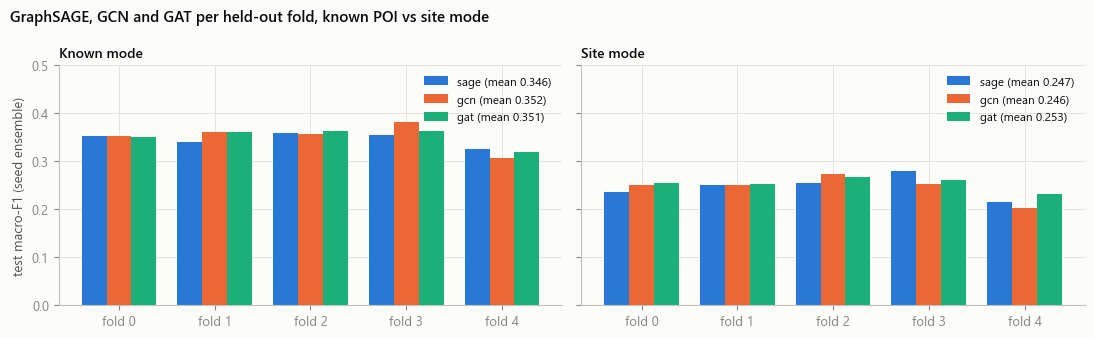

Selected on the validation score: sage (val score 0.315; sage 0.315, gcn 0.312, gat 0.313)
Minutes per CV run: sage 3.9, gcn 4.3, gat 16.7


In [8]:
cmp = summarise(cmp_tags)
BEST_TAG = cmp["val score"].idxmax()
BEST_BASE = {**BASE_CFG, "conv": RESULTS[BEST_TAG]["cfg"]["conv"]}

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
w, colours = 0.26, [BLUE, ORANGE, AQUA]
for ax, mode in zip(axes, MODES):
    for i, t in enumerate(cmp_tags):
        vals = [RESULTS[t]["fold_test"][mode][f] for f in range(N_FOLDS)]
        ax.bar(np.arange(N_FOLDS) + (i - 1) * w, vals, w, color=colours[i], label=f"{t} (mean {np.mean(vals):.3f})")
    ax.set_xticks(range(N_FOLDS), [f"fold {f}" for f in range(N_FOLDS)])
    ax.set_title(f"{mode.capitalize()} mode", fontsize=10)
    ax.legend(fontsize=8.5, loc="upper right", ncol=1)
axes[0].set_ylabel("test macro-F1 (seed ensemble)")
axes[0].set_ylim(0, 0.5)
fig.suptitle("GraphSAGE, GCN and GAT per held-out fold, known POI vs site mode", x=0.01, ha="left",
             fontsize=11, fontweight="semibold")
plt.tight_layout()
plt.show()

print(f"Selected on the validation score: {BEST_TAG} (val score {cmp.loc[BEST_TAG, 'val score']:.3f}; "
      + ", ".join(f"{t} {cmp.loc[t, 'val score']:.3f}" for t in cmp_tags) + ")")
print("Minutes per CV run: " + ", ".join(f"{t} {RESULTS[t]['minutes']:.1f}" for t in cmp_tags))
log(f"Architecture selected on the validation score: {BEST_TAG}")

**Findings.**

- **The three layer types are tied.** Validation scores are 0.315 (GraphSAGE), 0.313 (GAT) and 0.312 (GCN); test
  macro-F1 is 0.346 to 0.352 in known mode and 0.246 to 0.253 in site mode. Every difference is smaller than one
  fold's SD (0.012 to 0.025). **GraphSAGE is carried forward**: it has the highest validation score and trains about 4
  times faster than GAT (3.9 against 16.7 minutes per CV run).
- **Site mode reaches about 0.25, twice chance (0.125), with top-3 accuracy 0.75.** This is close to iteration 1's
  "geography only" ablation (0.235), now from the same model that classifies known POIs. Given only the location
  and its neighbourhood, the right category is among the model's three most likely in three cases out of four.
- **Known mode costs about 0.02** against iteration 1 under the same settings (0.346 against 0.367 for the
  3-seed tuned run), the price of sharing the weights with site mode. The mask rate controls this trade-off and is
  tuned next.
- **Label reuse makes no difference** (all settings within 0.003). Checks made while building this notebook showed
  why. Even with the true categories of all other validation nodes visible (93% of a node's neighbours labelled, the
  deployment condition), validation F1 does not rise, and a GNN given only neighbour categories (no features) reaches
  about 0.22. The co-location signal exists, but the location features (density, distances, neighbourhood shape,
  mapping profile of the area) already carry it. This is tested formally in the ablations.
- **Fold 4 (Maseru) is again the weakest** in site mode (0.20 to 0.23).

## 4. Tuning GraphSAGE

A random search of 12 configurations, plus the starting configuration from Section 3, over the usual settings
(width, depth, dropout, learning rate, weight decay, class-weight strength) and the new design choices: the
**mask rate** (share of loss nodes trained in site mode), the **label-rate range**, and the **distance scale**
(250 m, 1 km, 3 km, or plain mean). Each configuration runs the full 5-split spatial CV with 3 seeds; the ranking uses
the validation score only (mean of known-mode and site-mode validation macro-F1).

In [9]:
GRID = {"hidden": [64, 128], "layers": [1, 2, 3], "dropout": [0.3, 0.5], "lr": [5e-3, 1e-2],
        "weight_decay": [5e-3, 5e-2], "cw_power": [0.5, 0.75], "mask_rate": [0.3, 0.5, 0.7],
        "label_rate": [(0.1, 0.9), (0.0, 0.5)], "dist_scale": [None, 250, 1000, 3000]}
rng = np.random.default_rng(SEED)
tune_cfgs = []
while len(tune_cfgs) < 12:
    c = {k: v[rng.integers(len(v))] for k, v in GRID.items()}
    if c not in tune_cfgs and any(c[k] != BEST_BASE[k] for k in c):
        tune_cfgs.append(c)

RESULTS[f"{BEST_TAG}-base"] = RESULTS[BEST_TAG]
for i, c in enumerate(tune_cfgs):
    RESULTS[f"tune{i:02d}"] = run_cv({**BEST_BASE, **c}, tag=f"tune{i:02d}")

tune_tags = [f"{BEST_TAG}-base"] + [f"tune{i:02d}" for i in range(len(tune_cfgs))]
tune = summarise(tune_tags)
tune.insert(0, "config", [json.dumps({k: RESULTS[t]["cfg"][k] for k in GRID}) for t in tune_tags])
tune = tune.sort_values("val score", ascending=False)
with pd.option_context("display.max_colwidth", 200):
    print(tune.drop(columns=["acc known", "acc site", "top3 known"]).to_string())

BEST_TUNE = tune.index[0]
FINAL_CFG = RESULTS[BEST_TUNE]["cfg"]
print(f"\nSelected on the validation score: {BEST_TUNE} -> {json.dumps(FINAL_CFG)}")
log(f"Tuning selected {BEST_TUNE}: {json.dumps({k: FINAL_CFG[k] for k in GRID})}")

                                                                                                                                                                      config         reuse  val known  val site  val score  test known   SD k  test site   SD s  top3 site  epochs     min
run                                                                                                                                                                                                                                                                                       
tune05       {"hidden": 128, "layers": 2, "dropout": 0.5, "lr": 0.01, "weight_decay": 0.05, "cw_power": 0.75, "mask_rate": 0.3, "label_rate": [0.1, 0.9], "dist_scale": 250}  reuse 1x t.9      0.377     0.262      0.320       0.349  0.039      0.241  0.035      0.713    63.0   8.109
tune00     {"hidden": 64, "layers": 3, "dropout": 0.5, "lr": 0.005, "weight_decay": 0.005, "cw_power": 0.75, "mask_rate": 0.3, "label_rate": [0.0, 0.5]

**Findings.**

- **Selected: `tune05`**: GraphSAGE, hidden 128, 2 layers, dropout 0.5, learning rate 0.01, weight decay 0.05,
  class-weight power 0.75, mask rate 0.3, label rate 0.1 to 0.9, distance scale 250 m. Its validation score
  is 0.320 against 0.315 for the starting configuration. **That gain is within noise**: the 13 configurations
  span 0.306 to 0.320, and the top eight lie within 0.008 of each other. As in iteration 1, the limit is the
  information in the data, not the settings. The protocol selects on validation, so `tune05` is used. Its test
  scores (known 0.349, site 0.241) are no better than the starting configuration's (0.346, 0.247), which confirms
  that the ranking among the top configurations is noise.
- **The mask rate trades one mode against the other**, the one clear effect in the search. With 70% of the loss
  nodes in site mode, site-mode validation F1 is highest (0.255 to 0.270) and known mode lowest (0.353 to 0.361);
  with 30%, known mode is highest (0.368 to 0.377) and site mode 0.251 to 0.263. The validation score weights the
  two modes equally, so it settles in between.
- **Distance weighting has no consistent effect.** The two best configurations use 250 m and no weighting; 1 km and
  3 km appear throughout the ranking.
- **Stronger class weights (power 0.75) lower top-3 accuracy in site mode** (about 0.71 against 0.75 with power
  0.5). They move probability towards the small classes, which helps macro-F1 a little but pushes the frequent
  correct class out of the top three more often.

## 5. Final model: 5-seed ensemble in both modes

The selected configuration is retrained with 5 seeds per split (25 models). Each test fold is predicted by the
mean of its 5 models' temperature-scaled probabilities, in known mode and in site mode, at the reuse setting chosen
on validation. Reported: per-fold and pooled macro-F1, per-class precision, recall and F1, top-k accuracy, and
calibration (expected calibration error, ECE, with 15 bins) before and after temperature scaling.

In [11]:
FINAL_SEEDS = (0, 1, 2, 3, 4)
final = run_cv(FINAL_CFG, seeds=FINAL_SEEDS, tag="final", keep_models=True)
RESULTS["final"] = final


def ece(y, p, bins=15):
    """Expected calibration error of the top-class probability."""
    conf, pred = p.max(1), p.argmax(1)
    edges = np.linspace(0, 1, bins + 1)
    idx = np.clip(np.digitize(conf, edges[1:-1]), 0, bins - 1)
    return float(sum(np.abs((pred[idx == b] == y[idx == b]).mean() - conf[idx == b].mean()) * (idx == b).mean()
                     for b in range(bins) if (idx == b).any()))


yl = y_np[labelled]
print(f"Reuse setting chosen on validation: {final['best']}\n")
print(final["table"][["val known", "val site", "test known", "test site"]].round(3).to_string())

fold_tab = pd.DataFrame({"test nodes": [int(SPLITS[f]["test"].sum()) for f in range(N_FOLDS)],
                         "F1 known": [final["fold_test"]["known"][f] for f in range(N_FOLDS)],
                         "F1 site": [final["fold_test"]["site"][f] for f in range(N_FOLDS)]},
                        index=pd.Index(range(N_FOLDS), name="test fold"))
fold_tab.loc["mean"] = fold_tab.mean()
fold_tab.loc["SD"] = fold_tab.iloc[:N_FOLDS].std(ddof=0)
print("\n" + fold_tab.round(3).to_string())

summ = []
for m in MODES:
    p, p_raw = final["oof"][m][labelled], final["oof_raw"][m][labelled]
    temps = np.concatenate([final["temps"][m][f] for f in range(N_FOLDS)])
    summ.append({"mode": m, "macro-F1 pooled": macro_f1(yl, p.argmax(1)), "accuracy": (p.argmax(1) == yl).mean(),
                 "top-2": top_k(yl, p, 2), "top-3": top_k(yl, p, 3), "ECE raw": ece(yl, p_raw),
                 "ECE scaled": ece(yl, p), "log loss raw": -np.log(p_raw[np.arange(len(yl)), yl] + 1e-12).mean(),
                 "log loss scaled": -np.log(p[np.arange(len(yl)), yl] + 1e-12).mean(),
                 "T median": np.median(temps), "T range": f"{temps.min():.2f}-{temps.max():.2f}"})
print("\nPooled over all 5,952 labelled nodes (each predicted once, by the split that held its fold out):")
print(pd.DataFrame(summ).set_index("mode").round(3).to_string())

pc = {}
for m in MODES:
    pr, rc, f1c, sup = precision_recall_fscore_support(yl, final["oof"][m][labelled].argmax(1), labels=list(range(C)),
                                                       zero_division=0)
    top3c = [top_k(yl[yl == c], final["oof"][m][labelled][yl == c], 3) for c in range(C)]
    pc[m] = pd.DataFrame({"precision": pr, "recall": rc, "F1": f1c, "top-3": top3c}, index=CATS)
per_class = pd.concat(pc, axis=1)
per_class[("", "support")] = np.bincount(yl, minlength=C)
print("\nPer class (out-of-fold):")
print(per_class.round(3).to_string())

Reuse setting chosen on validation: reuse 1x t.5

              val known  val site  test known  test site
setting                                                 
no reuse          0.377     0.264       0.355      0.249
reuse 1x t.5      0.377     0.266       0.356      0.245
reuse 1x t.7      0.376     0.265       0.355      0.246
reuse 1x t.9      0.376     0.263       0.356      0.248
reuse 2x t.7      0.376     0.265       0.356      0.246

           test nodes  F1 known  F1 site
test fold                               
0            1182.000     0.388    0.261
1            1198.000     0.360    0.251
2            1183.000     0.372    0.255
3            1208.000     0.383    0.282
4            1181.000     0.280    0.176
mean         1190.400     0.356    0.245
SD             10.781     0.039    0.036

Pooled over all 5,952 labelled nodes (each predicted once, by the split that held its fold out):
       macro-F1 pooled  accuracy  top-2  top-3  ECE raw  ECE scaled  log loss raw  

**Findings.**

- **Known mode: test macro-F1 0.356 ± 0.039 over the 5 held-out folds (0.360 pooled), top-3 accuracy 0.83.**
  This is below iteration 1's 0.375 ± 0.021, mostly because of fold 4 (Maseru): 0.280 here against 0.348 in
  iteration 1. Folds 0 to 3 lie between 0.36 and 0.39, as before. Part of the cost comes from sharing the weights
  with site mode (about 0.02 in Section 3). The rest comes from the selected configuration: its stronger class
  weights and wider layers were chosen on a validation margin of 0.005, and they do worse on the urban fold
  (the starting configuration reached 0.325 there).
- **Site mode: test macro-F1 0.245 ± 0.036 (0.255 pooled), accuracy 0.39, top-3 accuracy 0.72.** From the location
  and its neighbourhood alone, with no information on how the place itself was mapped, the model is twice chance
  on areas it never saw, and in 72% of cases the true category is among its three most likely. This is the score
  behind any market-gap or site-suitability statement (RO3), and the one to quote for it.
- **What location reveals, per class (site mode):** Educational (F1 0.61, top-3 0.81), Infrastructure (0.42) and
  Retail (0.42, top-3 0.80) are recognisable from where they are. **Retail scores higher in site mode than in
  known mode** (0.42 against 0.38): shops are defined more by their surroundings (dense, central clusters) than by
  how they were mapped. Food & Beverage (0.08), Healthcare (0.08), Religious (0.12) and Other (0.14) are close to
  their chance level. Location alone does not tell them apart from Retail and Infrastructure, though their top-3
  accuracy (0.43 to 0.56) is still well above the three-in-eight a random guess would give.
- **The probabilities are already calibrated.** ECE is 0.038 (known) and 0.032 (site) before scaling, and the fitted
  temperatures are close to 1 (median 0.87 and 0.97). Temperature scaling leaves ECE unchanged and lowers log loss
  slightly. For RO3 this means summed site-mode probabilities can be read as expected counts, which is the property
  the market-gap comparison needs.
- **Label reuse** was chosen on validation (1 round, τ = 0.5), but every reuse setting lies within 0.004 of
  "no reuse" on test, so it has no practical effect (see Section 3).
- **Fold 4 (Maseru) is the weakest in both modes** (0.280 and 0.176). It is tested on the densest commercial area
  with few urban training examples, and 73% of its nodes have no labelled neighbour (Section 1).

## 6. Outputs

Written to `model_outputs_v2/`:

| File | Content |
|---|---|
| `gnn_dual_models.pt` | The 25 trained GraphSAGE models (5 splits x 5 seeds), configuration, feature list, own-node (masked) columns, class order, per-split scaler, temperatures and the reuse setting |
| `oof_predictions.csv` | Every labelled node with its true category, fold, and predicted category and 8 class probabilities in **known** and **site** mode (each node predicted by the ensemble that held its fold out) |
| `unlabelled_predictions.csv` | The 131 Uncategorized nodes with predicted probabilities in both modes, averaged over the 5 split ensembles |
| `metrics.json` | Architecture comparison, tuning table, final per-fold, pooled and per-class scores |
| `training_progress.log` | The training log shown live in the progress window |

In [12]:
ID_COLS = ["node_id", "osm_id", "name", "tag_key", "tag_value", "lon", "lat", "nearest_town", "adm1_name", "adm2_name"]

# Out-of-fold predictions, both modes
oof_df = df.loc[labelled, ID_COLS + ["category", "fold"]].copy()
for m in MODES:
    p = final["oof"][m][labelled]
    oof_df[f"pred_{m}"] = np.array(CATS)[p.argmax(1)]
    for c, cat in enumerate(CATS):
        oof_df[f"p_{m}_{cat}"] = p[:, c].round(5)
oof_df.to_csv(OUT_DIR / "oof_predictions.csv", index=False)

# Unlabelled nodes: outside the training folds in every split, so each split's ensemble predicts them
unl = ~labelled
unl_df = df.loc[unl, ID_COLS].copy()
for m in MODES:
    p = np.mean([final["probs"][m][f][unl] for f in range(N_FOLDS)], axis=0)
    unl_df[f"pred_{m}"] = np.array(CATS)[p.argmax(1)]
    for c, cat in enumerate(CATS):
        unl_df[f"p_{m}_{cat}"] = p[:, c].round(5)
unl_df.to_csv(OUT_DIR / "unlabelled_predictions.csv", index=False)

# Trained models with everything needed to rebuild the inputs
cont = [c for c in FEATS if c not in BINARY]
scalers = {f: {"mean": df.loc[fold_np != f, cont].mean().tolist(), "sd": df.loc[fold_np != f, cont].std(ddof=0).tolist()}
           for f in range(N_FOLDS)}
torch.save({"models": final["models"], "cfg": FINAL_CFG, "features": FEATS, "own_cols": OWN_COLS, "binary": BINARY,
            "continuous": cont, "scalers": scalers, "cats": CATS, "k": K, "reuse": final["best"],
            "reuse_settings": SETTINGS, "temperatures": final["temps"], "seeds": FINAL_SEEDS,
            "graph_note": "k=8 NN on x_km/y_km, undirected, self excluded; distance weights softmax(-d/dist_scale)"},
           OUT_DIR / "gnn_dual_models.pt")


def table_records(t):
    return json.loads(t.reset_index().to_json(orient="records"))


metrics = {
    "architecture_comparison": table_records(summarise(cmp_tags)), "selected_architecture": BEST_TAG,
    "tuning": table_records(tune), "selected_config": FINAL_CFG,
    "final": {"reuse_setting": final["best"], "reuse_table": table_records(final["table"]),
              "per_fold": table_records(fold_tab), "pooled": table_records(pd.DataFrame(summ)),
              "per_class": {m: table_records(pc[m]) for m in MODES}},
}
(OUT_DIR / "metrics.json").write_text(json.dumps(metrics, indent=1, default=str), encoding="utf-8")

for p in sorted(OUT_DIR.iterdir()):
    print(f"{p.name:30s} {p.stat().st_size / 1024:9.1f} KB")
chk = torch.load(OUT_DIR / "gnn_dual_models.pt", weights_only=False)
print(f"\nSaved {len(chk['models'])} models | reuse '{chk['reuse']}' | {len(chk['features'])} features "
      f"({len(chk['own_cols'])} masked in site mode)")
print("\nUnlabelled nodes (131): predicted category by mode")
print(pd.DataFrame({m: unl_df[f"pred_{m}"].value_counts() for m in MODES}).fillna(0).astype(int).to_string())
log("Outputs written; training finished")

gnn_dual_models.pt                8030.0 KB
metrics.json                        14.6 KB
oof_predictions.csv               1593.3 KB
training_progress.log              155.5 KB
unlabelled_predictions.csv          30.8 KB

Saved 25 models | reuse 'reuse 1x t.5' | 66 features (10 masked in site mode)

Unlabelled nodes (131): predicted category by mode
                known  site
Infrastructure    130   130
Retail              1     1


## 7. Ablations: what the model relies on (RO1)

Each ablation changes one thing in the selected configuration and reruns the full spatial CV with the same 3
seeds as its tuning run (`tune05`), which is the reference row. Reported: validation and test macro-F1 in both modes,
the change in test F1 against the reference, and the per-fold site-mode test F1.

| Ablation | Question |
|---|---|
| **graph off** (0 message-passing layers) | Does the graph add anything? Same encoder and classifier, but each node sees only its own features. This is the RO1 test. |
| **neighbour labels off** | Is the label trick (neighbour categories as inputs) worth keeping? |
| **neighbour labels only** (no features) | How much can co-location alone predict? Only the visible categories of the neighbours enter the model. |
| **mask rate 0 / 0.5 / 0.7 / 1** (reference 0.3) | The trade-off between the two modes. 0 is iteration 1's training (never in site mode); 1 trains in site mode only. |
| **no `osm_id_rank`** | Does the model lean on OSM mapping sessions? The 4 columns whose names contain `osm_id_rank` are removed. |
| **buffered CV (700 m)** | Training nodes within 700 m of a test-fold node are dropped from training, a stricter spatial test. |

In [14]:
REF = BEST_TUNE                                        # the selected configuration's 3-seed tuning run


def buffered_splits(buffer_m=700):
    """As SPLITS, but training nodes within buffer_m of any test-fold node are removed from training."""
    out = []
    for s in SPLITS:
        te_xy = xy[s["test"].numpy()]
        d, _ = cKDTree(te_xy).query(xy, k=1)
        tr = s["train"].numpy() & (d > buffer_m)
        out.append({**s, "train": torch.tensor(tr), "dropped": int(s["train"].sum()) - int(tr.sum())})
    return out


BUF_SPLITS = buffered_splits()
ABLATIONS = {
    "graph off": dict(cfg={"layers": 0}),
    "neighbour labels off": dict(cfg={"label_input": False}),
    "neighbour labels only": dict(feats=[]),
    "mask rate 0": dict(cfg={"mask_rate": 0.0}),
    "mask rate 0.5": dict(cfg={"mask_rate": 0.5}),
    "mask rate 0.7": dict(cfg={"mask_rate": 0.7}),
    "mask rate 1": dict(cfg={"mask_rate": 1.0}),
    "no osm_id_rank": dict(feats=[c for c in FEATS if c not in OSM_RANK]),
    "buffered CV (700 m)": dict(splits=BUF_SPLITS),
}
print("Buffered CV: training nodes dropped per split:", [s["dropped"] for s in BUF_SPLITS])
for name, a in ABLATIONS.items():
    RESULTS[f"abl: {name}"] = run_cv({**FINAL_CFG, **a.get("cfg", {})}, feats=a.get("feats", FEATS),
                                     splits=a.get("splits"), tag=f"abl: {name}")


def ablation_table():
    ref = RESULTS[REF]
    rows = []
    for name in [REF] + [f"abl: {n}" for n in ABLATIONS]:
        r = RESULTS[name]
        b = r["table"].loc[r["best"]]
        rows.append({"ablation": "reference (selected config)" if name == REF else name.removeprefix("abl: "),
                     "features": len(r["feats"]), "val known": b["val known"], "val site": b["val site"],
                     "test known": b["test known"], "d known": b["test known"] - ref["table"].loc[ref["best"], "test known"],
                     "test site": b["test site"], "d site": b["test site"] - ref["table"].loc[ref["best"], "test site"],
                     "top3 site": b["top3 site"],
                     **{f"site f{f}": r["fold_test"]["site"][f] for f in range(N_FOLDS)}})
    return pd.DataFrame(rows).set_index("ablation").round(3)


abl = ablation_table()
print(abl.to_string())

Buffered CV: training nodes dropped per split: [124, 145, 54, 248, 99]
                             features  val known  val site  test known  d known  test site  d site  top3 site  site f0  site f1  site f2  site f3  site f4
ablation                                                                                                                                                  
reference (selected config)        66      0.377     0.262       0.349    0.000      0.241   0.000      0.713    0.255    0.251    0.239    0.283    0.177
graph off                          66      0.376     0.247       0.356    0.007      0.240  -0.001      0.710    0.255    0.239    0.246    0.253    0.208
neighbour labels off               66      0.376     0.252       0.358    0.009      0.242   0.001      0.716    0.271    0.254    0.255    0.262    0.170
neighbour labels only               0      0.106     0.106       0.097   -0.252      0.095  -0.146      0.630    0.112    0.094    0.110    0.093    0.065

In [15]:
# Can message passing learn the neighbourhood itself? Local-only features (nothing computed from other POIs),
# with and without the graph
LOCAL = (["loc_x_km", "loc_y_km"] + [c for c in FEATS if c.startswith("adm_district_")]
         + [c for c in FEATS if c.startswith("attr_")])
assert not set(LOCAL) & {c for c in FEATS if c.startswith(("ctx_", "struct_"))}
print(f"Local-only features ({len(LOCAL)}): {LOCAL}")
ABLATIONS_LOCAL = {"local features only, graph on": dict(feats=LOCAL),
                   "local features only, graph off": dict(feats=LOCAL, cfg={"layers": 0})}
for name, a in ABLATIONS_LOCAL.items():
    RESULTS[f"abl: {name}"] = run_cv({**FINAL_CFG, **a.get("cfg", {})}, feats=a["feats"], tag=f"abl: {name}")
ABLATIONS.update(ABLATIONS_LOCAL)
abl = ablation_table()
print(abl.to_string())

Local-only features (20): ['loc_x_km', 'loc_y_km', 'adm_district_LSA', 'adm_district_LSB', 'adm_district_LSC', 'adm_district_LSD', 'adm_district_LSE', 'adm_district_LSF', 'adm_district_LSG', 'adm_district_LSH', 'adm_district_LSJ', 'adm_district_LSK', 'attr_has_name', 'attr_has_address', 'attr_has_hours', 'attr_has_footprint', 'attr_log_footprint_m2', 'attr_is_point', 'attr_quality_score', 'attr_osm_id_rank']
                                features  val known  val site  test known  d known  test site  d site  top3 site  site f0  site f1  site f2  site f3  site f4
ablation                                                                                                                                                     
reference (selected config)           66      0.377     0.262       0.349    0.000      0.241   0.000      0.713    0.255    0.251    0.239    0.283    0.177
graph off                             66      0.376     0.247       0.356    0.007      0.240  -0.001      0.710  

**Findings.** Changes smaller than about 0.015 are within seed and fold noise (the reference's fold SD is 0.03).

- **The GNN learns the neighbourhood from the graph (RO1).** With *local features only* (coordinates, district and
  the node's own mapping attributes; nothing computed from other POIs), message passing is worth **+0.078 in site
  mode** (0.218 against 0.140 with the graph off) and **+0.037 in known mode** (0.363 against 0.326). From the
  graph alone, the GNN recovers most of what the 46 hand-engineered neighbourhood features provide (site mode 0.218
  against 0.241 with all 66 features).
- **With the engineered features, the graph adds nothing more** (graph off: 0.356 / 0.240 against 0.349 / 0.241).
  The `ctx_`, `struct_` and `loc_` features were themselves computed from the k-NN graph (densities, distances, the
  32 nearest nodes' mapping profile, random-walk encodings), so they already hold what message passing would learn.
  For the write-up: the graph is the source of the neighbourhood signal either way, as engineered features or as
  learned messages, and the GNN reaches about the same accuracy by both routes.
- **Neighbour categories (co-location) add nothing on top of the features.** Turning the label trick off changes
  nothing (0.358 / 0.242). A model that sees only the training labels of the neighbours scores below chance (0.095),
  because with spatial folds 42 to 73% of held-out nodes have no labelled neighbour (Section 1). Section 8 measures
  the co-location signal in the deployment condition, where every other category is visible.
- **Training in site mode is what makes site mode work.** With mask rate 0 (iteration 1's training: attributes
  never hidden), hiding the attributes at test time gives 0.230; with 0.3 to 0.5 site mode reaches 0.241 to 0.257 at
  no cost in known mode (0.348 to 0.349). Above 0.5 known mode falls (0.337 at 0.7, 0.246 at 1, where the model
  never sees attributes). Mask rate 0.5 does best on test in site mode, but validation prefers 0.3 (0.320 against 0.316
  validation score), so the selected model is kept: the two are within noise.
- **No reliance on OSM mapping history, and no leakage across fold edges.** Without the 4 `osm_id_rank` columns the
  scores are unchanged (0.356 / 0.254); with a 700 m buffer between training and test nodes (54 to 248 training
  nodes dropped per split) they are also unchanged (0.351 / 0.249).

## 8. RO2: what shapes the business and amenity composition of an area

Both analyses use the 25 final models in **site mode**, on the test fold of each split (nodes those models never
trained on), so they describe what the model learned about *locations*, not about how POIs were mapped.

1. **Location characteristics: permutation importance.** One feature (or one feature group) at a time is shuffled
   across all nodes, which breaks its link to the category while keeping its distribution, and the held-out nodes
   are predicted again (in site mode, the test nodes masked in 10 groups). Importance is the rise in log loss and the
   drop in macro-F1, averaged over the 5 splits. Log loss is the main measure because it is far less noisy than
   macro-F1. "Neighbour categories" is treated as one more input: its importance is measured by hiding all visible
   labels.
2. **Neighbouring amenity types: occlusion.** In the deployment condition (the category of every other mapped POI
   is visible), the categories of all POIs of type A are hidden, and the change in each predicted class probability
   is measured for held-out nodes that have at least one type-A neighbour. The result is an 8 x 8 matrix: how much a
   neighbour's being known as type A raises or lowers the model's probability of each category, in percentage
   points.

Site-mode base (test folds): macro-F1 0.247, log loss 1.747

Feature groups and neighbour categories (rise in log loss when shuffled / hidden; mean over 5 splits):
                      d_log_loss      sd    d_F1
unit                                            
group: loc_               0.3117  0.1882 -0.0928
group: struct_            0.0091  0.0172 -0.0087
neighbour categories      0.0016  0.0006 -0.0005
group: adm_              -0.0115  0.0944 -0.0002
group: ctx_              -0.0274  0.1581 -0.0031

Top 15 single features:
                          d_log_loss      sd    d_F1
unit                                                
loc_log_density_100m          0.0433  0.0240 -0.0073
loc_log_knn16_dist_m          0.0289  0.0291  0.0004
loc_log_knn8_mean_dist_m      0.0271  0.0159 -0.0035
loc_log_density_2km           0.0229  0.0073 -0.0020
loc_log_nn1_dist_m            0.0217  0.0459 -0.0049
loc_log_density_250m          0.0196  0.0115  0.0003
adm_adm2_urban_share          0.0119  0.0096

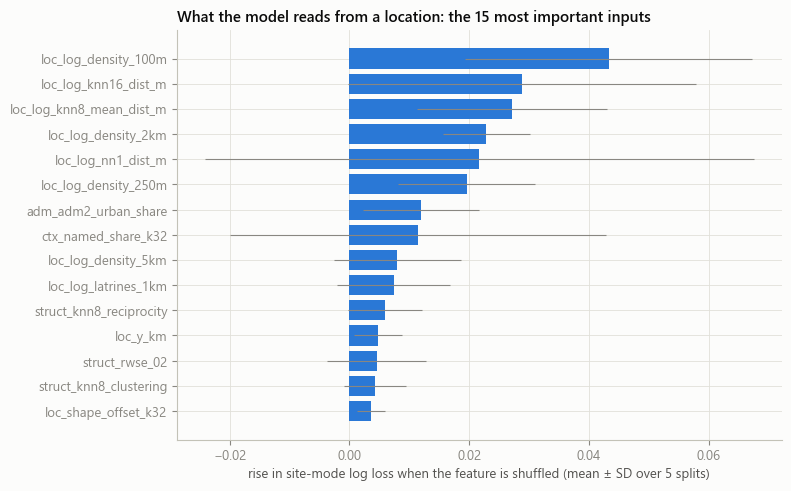

In [16]:
G_FINAL = make_graph(FINAL_CFG)
FINAL_MODELS = {f: [] for f in range(N_FOLDS)}
for rec in final["models"]:
    net = GNN(len(FEATS) + 1, C, **FINAL_CFG)
    net.load_state_dict(rec["state"])
    FINAL_MODELS[rec["fold"]].append(net.eval())
assert all(len(v) == len(FINAL_SEEDS) for v in FINAL_MODELS.values())
TEST_GROUPS = {f: SPLITS[f]["test"].nonzero().squeeze(1)[torch.randperm(int(SPLITS[f]["test"].sum()),
               generator=torch.Generator().manual_seed(f))].chunk(10) for f in range(N_FOLDS)}


def site_probs(f, x, own_idx, lab, groups=None):
    """Temperature-scaled 5-seed site-mode probabilities of split f's test nodes (masked in 10 groups); lab is the
    visible-label one-hot (or a function of the group returning it)."""
    p = torch.zeros(N, C)
    with torch.no_grad():
        for grp in (TEST_GROUPS[f] if groups is None else groups):
            xg = mask_own(x, own_idx, grp)
            lg = lab(grp) if callable(lab) else lab
            p[grp] = torch.stack([Fn.softmax(m(xg, G_FINAL, lg)[grp] / t, 1)
                                  for m, t in zip(FINAL_MODELS[f], final["temps"]["site"][f])]).mean(0)
    return p


def scores(f, p):
    te = SPLITS[f]["test"]
    yt, pt = Y[te].numpy(), p[te].numpy()
    return macro_f1(yt, pt.argmax(1)), float(-np.log(pt[np.arange(len(yt)), yt] + 1e-12).mean())


# Base scores and permutation importance (site mode, training labels visible as in the evaluation)
NON_OWN = [c for c in FEATS if c not in OWN_COLS]
UNITS = {**{f"group: {g}_": [c for c in NON_OWN if c.startswith(g + "_")] for g in GROUPS if g != "attr"},
         **{c: [c] for c in NON_OWN}}
perm_rng = np.random.default_rng(SEED)
PERM = torch.tensor(perm_rng.permutation(N))
imp_rows, t0 = [], time.time()
for f in range(N_FOLDS):
    x, own_idx = make_x(FEATS, f)
    lab_tr = label_features(SPLITS[f]["train"])
    f1_0, ll_0 = scores(f, site_probs(f, x, own_idx, lab_tr))
    imp_rows.append({"unit": "(none)", "fold": f, "F1": f1_0, "log loss": ll_0})
    f1_n, ll_n = scores(f, site_probs(f, x, own_idx, torch.zeros(N, C)))
    imp_rows.append({"unit": "neighbour categories", "fold": f, "F1": f1_n, "log loss": ll_n})
    for unit, cols in UNITS.items():
        xp = x.clone()
        j = [FEATS.index(c) for c in cols]
        xp[:, j] = x[PERM][:, j]
        f1_p, ll_p = scores(f, site_probs(f, xp, own_idx, lab_tr))
        imp_rows.append({"unit": unit, "fold": f, "F1": f1_p, "log loss": ll_p})
    log(f"  permutation importance: split {f} done ({time.time() - t0:.0f}s)")

imp = pd.DataFrame(imp_rows)
base = imp[imp["unit"] == "(none)"].set_index("fold")
imp["d log loss"] = imp["log loss"] - imp["fold"].map(base["log loss"])
imp["d F1"] = imp["F1"] - imp["fold"].map(base["F1"])
IMP = (imp[imp["unit"] != "(none)"].groupby("unit")
       .agg(d_log_loss=("d log loss", "mean"), sd=("d log loss", "std"), d_F1=("d F1", "mean"))
       .sort_values("d_log_loss", ascending=False))
print(f"Site-mode base (test folds): macro-F1 {base['F1'].mean():.3f}, log loss {base['log loss'].mean():.3f}\n")
print("Feature groups and neighbour categories (rise in log loss when shuffled / hidden; mean over 5 splits):")
print(IMP[IMP.index.str.startswith("group:") | (IMP.index == "neighbour categories")].round(4).to_string())
print("\nTop 15 single features:")
print(IMP[~IMP.index.str.startswith("group:") & (IMP.index != "neighbour categories")].head(15).round(4).to_string())

top = IMP[~IMP.index.str.startswith("group:")].head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.index, top["d_log_loss"], xerr=top["sd"], color=[ORANGE if u == "neighbour categories" else BLUE
                                                             for u in top.index], error_kw={"ecolor": MUTED, "lw": 0.8})
ax.set_xlabel("rise in site-mode log loss when the feature is shuffled (mean ± SD over 5 splits)")
ax.set_title("What the model reads from a location: the 15 most important inputs")
plt.tight_layout()
plt.show()

Site-mode macro-F1 on the test folds with every other category visible (deployment): 0.256 (training labels only: 0.247)

Change in the predicted probability of each category (columns, percentage points) when the categories of neighbouring POIs of type A (rows) are known rather than hidden; mean over held-out nodes with a type-A neighbour:
                       Infrastructure  Educational  Retail  Other  Food & Beverage  Tourism  Religious  Healthcare
Infrastructure known             1.44        -0.03   -0.55  -0.13            -0.31    -0.20      -0.19       -0.04
Educational known               -0.10         0.65   -0.21  -0.13            -0.16    -0.39       0.25        0.09
Retail known                    -0.67        -0.13    0.98  -0.09             0.22    -0.25      -0.12        0.07
Other known                     -0.14        -0.04    0.02   0.29            -0.03    -0.19      -0.07        0.15
Food & Beverage known           -0.16        -0.08    0.18  -0.04             0.19 

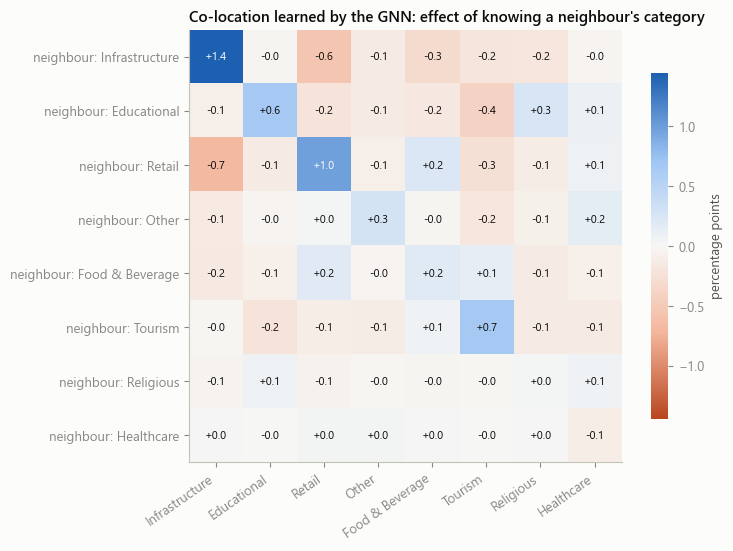

In [17]:
# Neighbour-type influence: hide the categories of all type-A POIs (deployment condition: every other label visible)
lab_all = torch.tensor(labelled)
src_np, dst_np = SRC.numpy(), DST.numpy()
infl_sum, infl_n = np.zeros((C, C)), np.zeros(C)
for f in range(N_FOLDS):
    x, own_idx = make_x(FEATS, f)

    def vis_except(grp, hide=None):
        vis = lab_all.clone()
        vis[grp] = False                                    # the targets never see their own label
        if hide is not None:
            vis &= Y != hide
        return label_features(vis)

    p_full = site_probs(f, x, own_idx, lambda grp: vis_except(grp))
    te = SPLITS[f]["test"].numpy()
    for a in range(C):
        p_hide = site_probs(f, x, own_idx, lambda grp: vis_except(grp, hide=a))
        has_a = np.zeros(N, bool)
        has_a[dst_np[labelled[src_np] & (y_np[src_np] == a)]] = True     # at least one type-A neighbour
        sel = te & has_a
        infl_sum[a] += (p_full - p_hide)[torch.tensor(sel)].sum(0).numpy()
        infl_n[a] += sel.sum()
    log(f"  neighbour influence: split {f} done")

INFL = pd.DataFrame(100 * infl_sum / infl_n[:, None], index=[f"{c} known" for c in CATS], columns=CATS)
f1_dep = np.mean([scores(f, site_probs(f, *make_x(FEATS, f), lambda grp: vis_except(grp)))[0] for f in range(N_FOLDS)])
print(f"Site-mode macro-F1 on the test folds with every other category visible (deployment): {f1_dep:.3f} "
      f"(training labels only: {base['F1'].mean():.3f})\n")
print("Change in the predicted probability of each category (columns, percentage points) when the categories of "
      "neighbouring POIs of type A (rows) are known rather than hidden; mean over held-out nodes with a type-A "
      "neighbour:")
print(INFL.round(2).to_string())
print("\nHeld-out nodes with at least one neighbour of each type:", dict(zip(CATS, infl_n.astype(int))))

lim = np.abs(INFL.to_numpy()).max()
fig, ax = plt.subplots(figsize=(7.6, 5.6))
DIV = LinearSegmentedColormap.from_list("div", ["#b8461f", "#f4b69c", "#f7f7f5", "#9ec5f4", "#1d5fb0"])
im = ax.imshow(INFL.to_numpy(), cmap=DIV, vmin=-lim, vmax=lim)
ax.set_xticks(range(C), CATS, rotation=35, ha="right")
ax.set_yticks(range(C), [f"neighbour: {c}" for c in CATS])
for i in range(C):
    for j in range(C):
        v = INFL.iat[i, j]
        ax.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=8, color=INK if abs(v) < 0.6 * lim else "white")
ax.grid(False)
cb = fig.colorbar(im, ax=ax, shrink=0.8)
cb.set_label("percentage points")
cb.outline.set_visible(False)
ax.set_title("Co-location learned by the GNN: effect of knowing a neighbour's category")
plt.tight_layout()
plt.show()

**Findings (RO2).**

- **Location characteristics shape the composition far more than neighbouring amenity types.** Shuffling the
  `loc_` group raises site-mode log loss by 0.31 and drops macro-F1 from 0.247 to 0.154. Hiding all neighbour
  categories changes log loss by 0.002. The `struct_` group adds a little (0.009). Shuffling the whole `adm_` or `ctx_`
  group gives mixed results across splits (mean below zero, SD 0.09 to 0.16): their columns are strongly correlated
  with each other and with `loc_`, so shuffling one group leaves the information in the others and creates
  combinations the model never saw. Their single-feature importances are the more reliable reading.
- **What the model reads from a location is how dense and how isolated it is.** The most important single inputs are
  the number of POIs within 100 m, the distance to the 16th and the mean distance to the 8 nearest POIs, the density
  within 2 km, the distance to the nearest POI and the density within 250 m. Next come the urban share of the
  sub-district, the named share of the 32 nearest POIs, and the household latrines within 1 km (a proxy for
  residential settlement). Retail and food outlets sit in dense, tightly spaced clusters; schools, churches and
  infrastructure sit in sparser settlements.
- **Neighbouring amenity types: weak but structured co-location.** With every other category visible (the deployment
  condition), site-mode macro-F1 rises only from 0.247 to 0.256. The occlusion matrix shows effects of at most 1.4
  percentage points, but with a consistent pattern:
  - *Like attracts like:* a known Infrastructure, Retail, Tourism or Educational neighbour raises the probability of
    the same category (+1.4, +1.0, +0.7 and +0.6 points).
  - *Retail and Food & Beverage go together* (+0.2 each way), and a Retail neighbour lowers the probability of
    Infrastructure (−0.7): commercial clusters are distinct from the scattered infrastructure of rural areas.
  - *Schools and churches co-locate:* a known Educational neighbour raises Religious (+0.3), consistent with
    church-founded schools.
  - *Healthcare is not predicted by its neighbours* (all effects ≤ 0.1 points): clinics do not cluster with any
    category, as chapter 1 (Section 1.6) anticipated.
- **For the write-up:** in Lesotho's OSM data the composition of an area is driven mainly by settlement density
  and spacing, which the GNN learns from the graph (Section 7) and which the engineered features also encode. The
  specific mix of neighbouring amenity types adds a real but small co-location signal, strongest for commercial
  clusters (Retail, Food & Beverage) and tourism.

## 9. RO3: market gaps and clusters per sub-district

**Method: expected against observed composition.** For every mapped POI, the out-of-fold site-mode probabilities
say what its location and surroundings resemble, from models that never saw its area. Summed over a sub-district
they give the **expected** number of POIs of each category; the **observed** number is what is mapped there.

- **Gap** (expected > observed): more places in the sub-district look like locations of category *c* than are
  mapped as *c*. This is a candidate under-supplied category.
- **Cluster** (observed > expected): category *c* is mapped more often than the locations alone suggest (an
  established concentration, or competition).

**Testing.** If the probabilities are calibrated (Section 5: ECE 0.03), the observed count is a sum of independent
Bernoulli outcomes with mean *E* and variance Σ p(1 − p). The z-score (*E* − *O*) / √Var flags a **gap** when
z ≥ 2 and *E* − *O* ≥ 2 POIs, and a **cluster** when z ≤ −2 and *O* − *E* ≥ 2. Sub-districts with fewer than 20
labelled POIs are not flagged.

**National prior correction.** Class weights in training raise the probabilities of the small classes, so before
summing, one multiplicative factor per category is fitted (iterative proportional fitting) so that the national
expected totals equal the observed totals. Gaps are therefore relative to the national relationship between
locations and categories, not to the training weights.

**Mapping caveat (chapter 1, Section 1.6).** A sub-district that is thinly mapped can look underserved because
its POIs are missing, not because they do not exist. Each sub-district is marked `thin` when its mean mapping
quality (share of name, address, hours and outline) is in the lowest quarter of sub-districts.

**Candidate sites** inside an area are scored with `predict_poi.py` (`site` for one location, `suggest` for the best
spots for a category around a location), which runs these same 25 models in site mode on a location added to the
graph. Its `--check` confirms that it reproduces this notebook's site-mode predictions.

In [18]:
P_SITE = final["oof"]["site"][labelled]                 # out-of-fold, temperature-scaled site-mode probabilities
lab_df = df.loc[labelled, ["adm1_name", "adm2_name", "adm2_pcode", "attr_quality_score", "lon", "lat"]].reset_index(drop=True)
y_lab = y_np[labelled]
obs_nat = np.bincount(y_lab, minlength=C).astype(float)

# National prior correction: one factor per category so that expected totals equal observed totals
w_prior = np.ones(C)
for _ in range(200):
    q = P_SITE * w_prior
    q /= q.sum(1, keepdims=True)
    w_prior *= obs_nat / q.sum(0)
P_ADJ = P_SITE * w_prior
P_ADJ /= P_ADJ.sum(1, keepdims=True)
print(pd.DataFrame({"observed": obs_nat.astype(int), "expected before correction": P_SITE.sum(0).round(0),
                    "factor": (w_prior / w_prior[0]).round(3), "expected after": P_ADJ.sum(0).round(0)},
                   index=CATS).to_string())
print(f"Site-mode macro-F1 with the corrected probabilities (pooled out-of-fold): "
      f"{macro_f1(y_lab, P_ADJ.argmax(1)):.3f} (before {macro_f1(y_lab, P_SITE.argmax(1)):.3f}); "
      f"ECE {ece(y_lab, P_ADJ):.3f} (before {ece(y_lab, P_SITE):.3f})")

rows = []
quality = lab_df.groupby("adm2_pcode")["attr_quality_score"].mean()
thin_cut = quality.quantile(0.25)
for pc_, idx in lab_df.groupby("adm2_pcode").groups.items():
    idx = np.asarray(idx)
    r0 = lab_df.loc[idx[0]]
    p = P_ADJ[idx]
    for c, cat in enumerate(CATS):
        e, o, var = p[:, c].sum(), (y_lab[idx] == c).sum(), (p[:, c] * (1 - p[:, c])).sum()
        z = (e - o) / np.sqrt(var) if var > 0 else 0.0
        signal = ""
        if len(idx) >= 20:
            if z >= 2 and e - o >= 2:
                signal = "gap"
            elif z <= -2 and o - e >= 2:
                signal = "cluster"
        rows.append({"adm1_name": r0["adm1_name"], "adm2_name": r0["adm2_name"], "adm2_pcode": pc_, "category": cat,
                     "pois": len(idx), "observed": int(o), "expected": round(e, 2), "gap": round(e - o, 2),
                     "z": round(z, 2), "signal": signal, "mapping": "thin" if quality[pc_] <= thin_cut else "",
                     "lon": lab_df.loc[idx, "lon"].mean(), "lat": lab_df.loc[idx, "lat"].mean()})
GAPS = pd.DataFrame(rows)
GAPS.drop(columns=["lon", "lat"]).to_csv(OUT_DIR / "market_gaps.csv", index=False)

n_sub = GAPS["adm2_pcode"].nunique()
n_elig = GAPS.loc[GAPS["pois"] >= 20, "adm2_pcode"].nunique()
print(f"\n{n_sub} sub-districts, {n_elig} with at least 20 labelled POIs; flagged cells:")
print(pd.crosstab(GAPS["category"], GAPS["signal"]).reindex(CATS).drop(columns="", errors="ignore").to_string())
BUSINESS = ["Retail", "Food & Beverage", "Healthcare", "Tourism"]
show_cols = ["adm1_name", "adm2_name", "adm2_pcode", "category", "pois", "observed", "expected", "gap", "z", "mapping"]
print("\nLargest gaps in business and service categories (Retail, Food & Beverage, Healthcare, Tourism):")
print(GAPS[GAPS["category"].isin(BUSINESS) & GAPS["signal"].eq("gap")].sort_values("z", ascending=False)[show_cols]
      .head(15).to_string(index=False))
print("\nStrongest clusters in the same categories:")
print(GAPS[GAPS["category"].isin(BUSINESS) & GAPS["signal"].eq("cluster")].sort_values("z")[show_cols]
      .head(10).to_string(index=False))

                 observed  expected before correction  factor  expected after
Infrastructure       1792                      1034.0   1.000          1792.0
Educational          1666                      1005.0   1.048          1666.0
Retail               1181                       807.0   0.612          1181.0
Other                 334                       583.0   0.250           334.0
Food & Beverage       293                       652.0   0.180           293.0
Tourism               252                       587.0   0.210           252.0
Religious             236                       588.0   0.204           236.0
Healthcare            198                       695.0   0.108           198.0
Site-mode macro-F1 with the corrected probabilities (pooled out-of-fold): 0.224 (before 0.255); ECE 0.035 (before 0.036)

78 sub-districts, 67 with at least 20 labelled POIs; flagged cells:
signal           cluster  gap
category                     
Infrastructure         6    4
Educational       

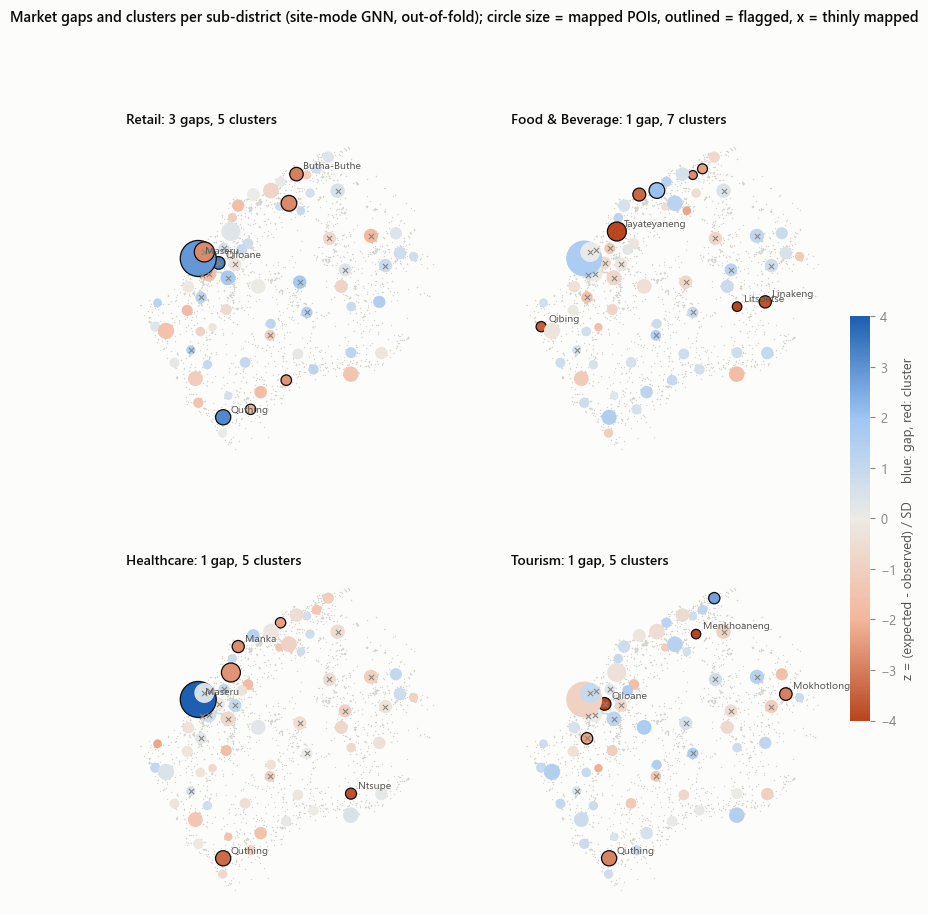

mapping  normal  thin  All
signal                    
cluster      33     7   40
gap          12     5   17
All          45    12   57


In [21]:
fig, axes = plt.subplots(2, 2, figsize=(11, 10.5))
DIV_Z = LinearSegmentedColormap.from_list("div_z", ["#b8461f", "#f4b69c", "#ecebe6", "#9ec5f4", "#1d5fb0"])
for ax, cat in zip(axes.ravel(), BUSINESS):
    ax.scatter(df["lon"], df["lat"], s=1, c="#d6d5ce", lw=0)
    g = GAPS[GAPS["category"].eq(cat) & (GAPS["pois"] >= 20)]
    sc = ax.scatter(g["lon"], g["lat"], s=12 + 2.2 * np.sqrt(g["pois"]) ** 1.6, c=g["z"].clip(-4, 4), cmap=DIV_Z,
                    vmin=-4, vmax=4, edgecolors=np.where(g["signal"].ne(""), INK, "none"), linewidths=0.9)
    thin = g[g["mapping"].eq("thin")]
    ax.scatter(thin["lon"], thin["lat"], marker="x", s=14, c=MUTED, lw=0.8)
    for _, r in g[g["signal"].ne("")].assign(az=lambda t: t["z"].abs()).nlargest(4, "az").iterrows():
        ax.annotate(r["adm2_name"].split(" (")[0], (r["lon"], r["lat"]), xytext=(5, 4), textcoords="offset points",
                    fontsize=7.5, color=INK2)
    n_gap, n_cl = int((g["signal"] == "gap").sum()), int((g["signal"] == "cluster").sum())
    ax.set_title(f"{cat}: {n_gap} gap{'s' * (n_gap != 1)}, {n_cl} cluster{'s' * (n_cl != 1)}", fontsize=10)
    ax.set_aspect(1 / np.cos(np.deg2rad(29.5)))
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
cb = fig.colorbar(sc, ax=axes, shrink=0.5, pad=0.02)
cb.set_label("z = (expected - observed) / SD     blue: gap, red: cluster")
cb.outline.set_visible(False)
fig.suptitle("Market gaps and clusters per sub-district (site-mode GNN, out-of-fold); circle size = mapped POIs, "
             "outlined = flagged, x = thinly mapped", x=0.02, ha="left", fontsize=10.5, fontweight="semibold")
plt.show()

# How the flagged gaps relate to mapping completeness
flag = GAPS[GAPS["signal"].ne("")]
print(pd.crosstab(flag["signal"], flag["mapping"].replace("", "normal"), margins=True).to_string())

**Findings (RO3).**

- **The national correction is large for the small classes.** The class-weighted model expects 2 to 3.5 times as many
  Healthcare, Food & Beverage, Tourism, Religious and Other POIs as are mapped (factors 0.11 to 0.25). After the
  correction the probabilities are as well calibrated as before (ECE 0.035) and suited to counting. They are not
  suited to classifying: macro-F1 falls from 0.255 to 0.224, because the weights exist to recover the small classes.
  The corrected probabilities are used only for the expected counts.
- **57 flagged cells in the 67 sub-districts with at least 20 POIs: 17 gaps and 40 clusters.** Clusters outnumber
  gaps: most categories are more concentrated than the locations alone would suggest. This is the co-location of
  Section 8 seen at district scale.
- **Gaps in business and service categories:**
  - **Maseru town (LSA12): Healthcare** (70 mapped against 107 expected, z = 4.0) and **Retail** (433 against 479,
    z = 2.9). The capital has many places that look like clinic or shop locations but are mapped as something else.
  - **Quthing town (LSG06): Retail** (33 against 48, z = 3.2).
  - **Qiloane (LSA01): Retail** (0 against 8). This sub-district is thinly mapped, so the gap may come from missing
    data rather than missing shops.
  - **Ngoajane (LSB01): Tourism** (0 against 5) and **Leribe (LSC13): Food & Beverage** (6 against 13).
- **Clusters:** Food & Beverage in Teyateyaneng (24 against 11) and Maputsoe (10 against 4), border and transit towns
  on the main north road, and in small mountain centres (Litsoetse, Linakeng, Qibing). Retail in Butha-Buthe town
  (34 against 22). Tourism in Qiloane and Menkhoaneng. Healthcare in Quthing and Ntsupe.
- **Mapping caveat:** 12 of the 57 flagged cells (5 of the 17 gaps) lie in thinly mapped sub-districts and are
  marked `thin` in `market_gaps.csv`. They need checking on the ground before anyone acts on them.
- **For the write-up:** a gap means the *locations* in an area resemble where a category is found elsewhere in
  Lesotho, but the category is mapped there less often than expected. That makes it a hypothesis about unmet demand
  or missing data, not evidence of profitability (chapter 1, Section 1.6). It is the input to the naturalistic
  evaluation with business owners (RO4).

In [22]:
metrics = json.loads((OUT_DIR / "metrics.json").read_text(encoding="utf-8"))
metrics["ablations"] = table_records(abl)
metrics["ro2_permutation_importance"] = table_records(IMP.round(5))
metrics["ro2_neighbour_influence_pp"] = table_records(INFL.round(3))
metrics["ro2_site_f1_deployment"] = round(float(f1_dep), 4)
metrics["ro3_prior_factors"] = dict(zip(CATS, (w_prior / w_prior[0]).round(4).tolist()))
metrics["ro3_flagged"] = table_records(GAPS[GAPS["signal"].ne("")].drop(columns=["lon", "lat"])
                                       .sort_values(["signal", "z"]).set_index("adm2_pcode"))
(OUT_DIR / "metrics.json").write_text(json.dumps(metrics, indent=1, default=str), encoding="utf-8")

for p in sorted(OUT_DIR.iterdir()):
    print(f"{p.name:30s} {p.stat().st_size / 1024:9.1f} KB")
print("\nmetrics.json sections:", list(metrics))
log("Ablations, RO2 and RO3 results written; notebook complete")

gnn_dual_models.pt                8030.0 KB
market_gaps.csv                     38.1 KB
metrics.json                        42.2 KB
oof_predictions.csv               1593.3 KB
training_progress.log              269.6 KB
unlabelled_predictions.csv          30.8 KB

metrics.json sections: ['architecture_comparison', 'selected_architecture', 'tuning', 'selected_config', 'final', 'ablations', 'ro2_permutation_importance', 'ro2_neighbour_influence_pp', 'ro2_site_f1_deployment', 'ro3_prior_factors', 'ro3_flagged']


## 10. Summary by research objective

| Objective | Result from this one model |
|---|---|
| **RO1:** develop a GNN that learns spatial and neighbourhood relationships | GraphSAGE (distance-weighted, residual, jumping knowledge) trained in two modes; GCN and GAT tie with it. With local features only, message passing adds **+0.08 macro-F1 in site mode** (0.218 against 0.140) and +0.04 in known mode: the GNN learns the neighbourhood from the graph. With the engineered neighbourhood features it reaches the same accuracy, and the graph adds nothing further. |
| **RO2:** which neighbouring amenity types and location characteristics shape composition | **Settlement density and spacing** dominate (POIs within 100 m and 2 km, distances to the 8th and 16th nearest POI). **Neighbouring types add a small, structured co-location signal**: like attracts like, Retail with Food & Beverage, schools with churches; Healthcare follows no neighbour pattern. |
| **RO3:** underserved areas and market gaps | 17 gaps and 40 clusters in 67 sub-districts (`market_gaps.csv`). Business gaps include Healthcare and Retail in Maseru town and Retail in Quthing; Food & Beverage clusters along the northern corridor. 5 of the gaps are in thinly mapped areas. Candidate sites are scored with `predict_poi.py` (`site`, `suggest`). |
| **RO4:** predictive performance (artificial evaluation) | Spatial 5-fold CV on unseen areas. **Known mode: macro-F1 0.356 ± 0.039, top-3 0.83. Site mode: 0.245 ± 0.036, top-3 0.72** (chance 0.125). Calibrated (ECE 0.03). Unchanged without OSM id history and with a 700 m buffer. The naturalistic half (business owners judging the recommendations) is fieldwork. |

**Limits to report.**

- Site mode is twice chance overall, but it is reliable only for Educational, Infrastructure and Retail. For Food &
  Beverage, Healthcare, Religious and Other it is near chance on its own, and useful only as a top-3 shortlist.
- The urban Maseru fold is the weakest in both modes (0.28 / 0.18).
- The selected configuration won tuning by a margin within noise. Mask rate 0.5 scored better on test in site mode
  (0.257), but validation preferred 0.3.
- Neighbour categories (the label trick and label reuse) add little: the co-location signal is real but small.
- Market gaps compare locations with the mapped categories. They inherit OSM's uneven coverage and say nothing
  about profitability.